# Filogenia de cinco mamíferos con COX1
Carlota Ayala Pérez y Lucía Criz Toste · Bioinformática · Tema 6

Tomamos como punto de partida el ejemplo de UPGMA con el gen mitocondrial **COX1** de los apuntes y repetimos el procedimiento con gato, león, tigre, perro y zorro. Sobre el mismo alineamiento aplicamos UPGMA, Neighbor-Joining y máxima parsimonia para comparar qué agrupaciones recupera cada método.

**Para ejecutar.** Se necesitan Biopython y Matplotlib. Si faltan, ejecuta `%pip install biopython matplotlib` en una celda de Jupyter. La primera ejecución descarga los registros de NCBI y requiere Internet. Las siguientes reutilizan los archivos GenBank guardados en `datos_cox1`.

## 1. Descarga de los registros y extracción de COX1
Se recupera cada registro GenBank por su accesión con versión. Se busca la CDS anotada como COX1 y se extrae respetando sus coordenadas y orientación. Los archivos se guardan después de validar su contenido.

In [1]:
from Bio import SeqIO, Phylo
from Bio.Align import PairwiseAligner, substitution_matrices
from Bio.Phylo.TreeConstruction import DistanceTreeConstructor, DistanceMatrix
from Bio.Phylo.BaseTree import Tree, Clade
from itertools import combinations
from collections import Counter
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image
from html import escape

def tabla(cabeceras, filas):
    cabecera = ''.join(f'<th>{escape(str(x))}</th>' for x in cabeceras)
    cuerpo = ''.join('<tr>' + ''.join(f'<td>{escape(str(x))}</td>' for x in fila) + '</tr>' for fila in filas)
    display(HTML(f'<table><thead><tr>{cabecera}</tr></thead><tbody>{cuerpo}</tbody></table>'))

In [2]:
import urllib.request
import urllib.parse
from io import StringIO

accesiones = {
    "Gato": "NC_001700.1",
    "León": "NC_028302.1",
    "Tigre": "NC_010642.1",
    "Perro": "NC_002008.4",
    "Zorro": "NC_008434.1",
}
carpeta = Path("datos_cox1")
carpeta.mkdir(exist_ok=True)
secuencias_cds = {}
filas = []

for especie, accesion in accesiones.items():
    archivo = carpeta / f"{accesion}.gb"
    if archivo.exists():
        texto = archivo.read_text(encoding="utf-8")
        origen = "Copia local"
    else:
        parametros = urllib.parse.urlencode({
            "id": accesion, "db": "nuccore",
            "report": "genbank", "retmode": "text"
        })
        url = "https://www.ncbi.nlm.nih.gov/sviewer/viewer.fcgi?" + parametros
        with urllib.request.urlopen(url, timeout=60) as respuesta:
            texto = respuesta.read().decode("utf-8")
        origen = "Descargado de NCBI"

    registro = SeqIO.read(StringIO(texto), "genbank")
    assert registro.id == accesion
    genes = [
        elemento for elemento in registro.features
        if elemento.type == "CDS"
        and elemento.qualifiers.get("gene") == ["COX1"]
    ]
    assert len(genes) == 1, f"Se esperaba una CDS COX1 en {accesion}"
    gen = genes[0]
    cds = gen.extract(registro.seq)
    assert str(cds.translate(table=2, cds=True)) == gen.qualifiers["translation"][0]
    secuencias_cds[especie] = str(cds)
    archivo.write_text(texto, encoding="utf-8")
    inicio = int(gen.location.start) + 1
    fin = int(gen.location.end)
    hebra = "+" if gen.location.strand == 1 else "−"
    filas.append([especie, accesion, f"{inicio}–{fin}", hebra, len(cds), origen])

tabla(["Especie", "Registro NCBI", "CDS (GenBank)", "Hebra", "Longitud CDS", "Procedencia"], filas)


Especie,Registro NCBI,CDS (GenBank),Hebra,Longitud CDS,Procedencia
Gato,NC_001700.1,6216–7760,+,1545,Descargado de NCBI
León,NC_028302.1,6033–7577,+,1545,Descargado de NCBI
Tigre,NC_010642.1,6280–7824,+,1545,Descargado de NCBI
Perro,NC_002008.4,5349–6893,+,1545,Descargado de NCBI
Zorro,NC_008434.1,5350–6894,+,1545,Descargado de NCBI


## 2. Alineamiento por codones
Se elimina TAA y se verifica que las proteínas se alinean globalmente frente a la del gato sin huecos. Como no hay inserciones ni deleciones en esas comparaciones, cada aminoácido corresponde a un codón en la misma posición de las cinco secuencias.

In [3]:
from Bio.Seq import Seq

names = list(secuencias_cds)
seq = {}
prots = {}
for nombre, cds in secuencias_cds.items():
    assert len(cds) == 1545 and cds.endswith("TAA")
    prots[nombre] = str(Seq(cds).translate(table=2, cds=True))
    seq[nombre] = cds[:-3]

alineador = PairwiseAligner()
alineador.mode = "global"
alineador.substitution_matrix = substitution_matrices.load("BLOSUM62")
alineador.open_gap_score = -11
alineador.extend_gap_score = -1
for nombre in names[1:]:
    alineamiento = alineador.align(prots[names[0]], prots[nombre])[0]
    assert alineamiento.shape == (2, 514)
    assert alineamiento.aligned.tolist() == [[[0, 514]], [[0, 514]]]

N = 1542
assert all(len(s) == N and set(s) <= set("ACGT") for s in seq.values())
print(f"{len(names)} secuencias, {N} columnas comparables y ningún hueco.")
tabla(["Especie", "Primeros 30 nucleótidos"], [[nombre, seq[nombre][:30]] for nombre in names])

5 secuencias, 1542 columnas comparables y ningún hueco.


Especie,Primeros 30 nucleótidos
Gato,ATGTTCATAAACCGGTGACTATTTTCAACT
León,ATGTTCATAAACCGCTGACTATTTTCAACC
Tigre,ATGTTCATAAACCGCTGACTATTTTCAACC
Perro,ATGTTCATTAACCGATGACTGTTCTCCACT
Zorro,ATGTTCATTAATCGATGATTATTCTCTACT


## 3. Distancia p
Para cada pareja se cuentan las bases distintas y se divide por 1.542. La diagonal es cero porque cada secuencia coincide consigo misma.

In [4]:
diff={(a,b):sum(x!=y for x,y in zip(seq[a],seq[b])) for a in names for b in names}
d={(a,b):c/N for (a,b),c in diff.items()}
dm=DistanceMatrix(names,[[d[a,b] for b in names[:i+1]] for i,a in enumerate(names)])

tabla(["Pareja", "Diferencias", "Distancia p"],
      [[f"{a}–{b}", diff[a,b], f"{d[a,b]:.4f}"] for a,b in combinations(names,2)])
tabla(["Especie"] + names,
      [[a] + [f"{d[a,b]:.4f}" for b in names] for a in names])

Pareja,Diferencias,Distancia p
Gato–León,197,0.1278
Gato–Tigre,201,0.1304
Gato–Perro,297,0.1926
Gato–Zorro,298,0.1933
León–Tigre,144,0.0934
León–Perro,310,0.2010
León–Zorro,315,0.2043
Tigre–Perro,309,0.2004
Tigre–Zorro,304,0.1971
Perro–Zorro,233,0.1511


Especie,Gato,León,Tigre,Perro,Zorro
Gato,0.0000,0.1278,0.1304,0.1926,0.1933
León,0.1278,0.0000,0.0934,0.2010,0.2043
Tigre,0.1304,0.0934,0.0000,0.2004,0.1971
Perro,0.1926,0.2010,0.2004,0.0000,0.1511
Zorro,0.1933,0.2043,0.1971,0.1511,0.0000


## 4. UPGMA
Se seleccionan los grupos con menor distancia media entre sus miembros. La altura del nuevo nodo es la mitad de esa distancia. La longitud de cada rama es la diferencia entre las alturas del padre y del hijo.

In [5]:
groups={(a,):(Clade(name=a),0) for a in names};steps=[]
def mean(a,b):return sum(d[x,y] for x in a for y in b)/(len(a)*len(b))
while len(groups)>1:
 a,b=min(combinations(groups,2),key=lambda t:mean(*t))
 v=mean(a,b);h=v/2
 ca,ha=groups.pop(a);cb,hb=groups.pop(b);ca.branch_length=h-ha;cb.branch_length=h-hb
 groups[a+b]=(Clade(clades=[ca,cb]),h)
 steps.append([', '.join(a),', '.join(b),v,h,h-ha,h-hb])
up=Tree(next(iter(groups.values()))[0],rooted=True)

tabla(["Grupo 1", "Grupo 2", "Distancia media", "Altura"],
      [[a,b,f"{distancia:.4f}",f"{altura:.4f}"] for a,b,distancia,altura,_,_ in steps])

Grupo 1,Grupo 2,Distancia media,Altura
León,Tigre,0.0934,0.0467
Gato,"León, Tigre",0.1291,0.0645
Perro,Zorro,0.1511,0.0756
"Gato, León, Tigre","Perro, Zorro",0.1981,0.0991


## 5. Neighbor-Joining
Se calcula Q para identificar el primer par que une NJ. Con cinco especies, NJ puede distinguir dos separaciones internas. Se muestran las del árbol no enraizado.

In [6]:
nj = DistanceTreeConstructor().nj(dm)
totales = {a: sum(d[a, b] for b in names) for a in names}
criterio_q = sorted(
    ((len(names) - 2) * d[a, b] - totales[a] - totales[b], a, b)
    for a, b in combinations(names, 2)
)
tabla(["Pareja", "Q inicial"], [[f"{a}–{b}", f"{q:.4f}"] for q, a, b in criterio_q])

q_min, especie_a, especie_b = criterio_q[0]
print(f"Primera pareja según Q: {especie_a}–{especie_b} ({q_min:.4f}).")
for clado in nj.get_nonterminals()[1:]:
    hojas = {terminal.name for terminal in clado.get_terminals()}
    if len(hojas) > len(names) / 2:
        hojas = set(names) - hojas
    print("Separación:", ", ".join(a for a in names if a in hojas), "|",
          ", ".join(a for a in names if a not in hojas))

Primera pareja según Q: Perro–Zorro (-1.0376).
Separación: León, Tigre | Gato, Perro, Zorro
Separación: Perro, Zorro | Gato, León, Tigre


Pareja,Q inicial
Perro–Zorro,-1.0376
León–Tigre,-0.9676
Gato–León,-0.8872
Gato–Tigre,-0.8742
Gato–Perro,-0.8113
Gato–Zorro,-0.8100
Tigre–Zorro,-0.7756
León–Perro,-0.7685
Tigre–Perro,-0.7652
León–Zorro,-0.7594


## 6. Árboles y comparación de las distancias
El dibujo de NJ es rectangular para facilitar su lectura. El punto de partida del dibujo no constituye una raíz biológica.

RMSE de UPGMA: 0.0033
RMSE de Neighbor-Joining: 0.0016


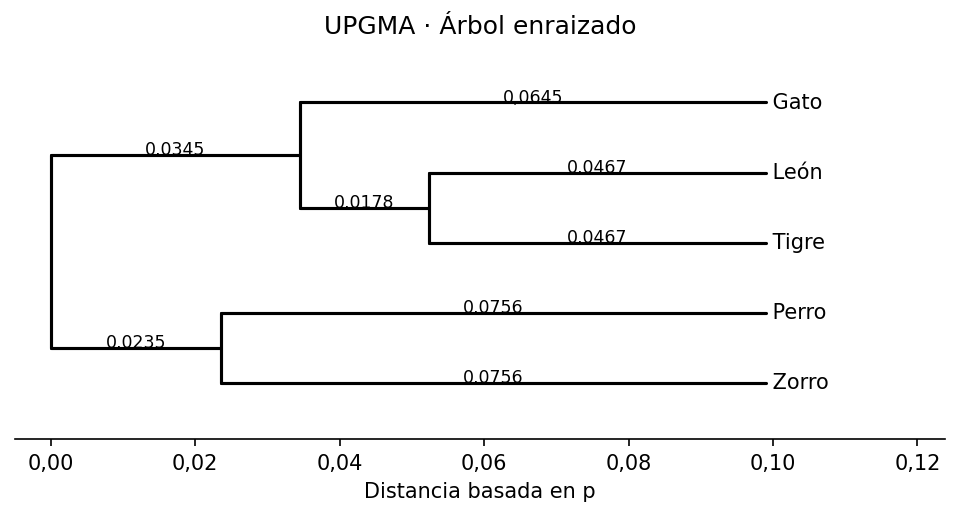

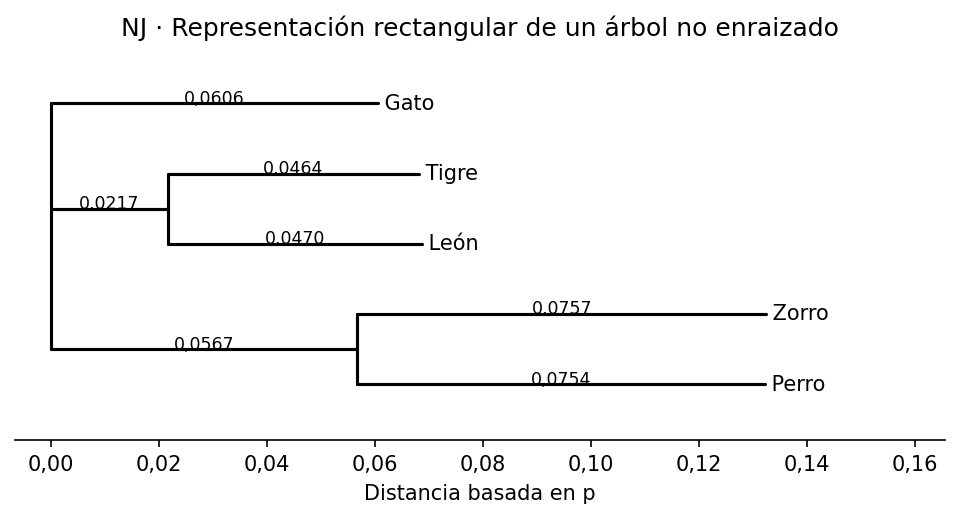

Pareja,Distancia p,Distancia en UPGMA,Distancia en NJ
Gato–León,0.1278,0.1291,0.1294
Gato–Tigre,0.1304,0.1291,0.1287
Gato–Perro,0.1926,0.1981,0.1928
Gato–Zorro,0.1933,0.1981,0.1930
León–Tigre,0.0934,0.0934,0.0934
León–Perro,0.2010,0.1981,0.2009
León–Zorro,0.2043,0.1981,0.2011
Tigre–Perro,0.2004,0.1981,0.2003
Tigre–Zorro,0.1971,0.1981,0.2005
Perro–Zorro,0.1511,0.1511,0.1511


In [7]:
from io import BytesIO
def show(tree, title):
 fig,ax=plt.subplots(figsize=(8,3.4));Phylo.draw(tree,axes=ax,do_show=False,show_confidence=False,label_func=lambda cl:cl.name if cl.is_terminal() else None,branch_labels=lambda c:f'{c.branch_length:.4f}'.replace('.',',') if c.branch_length else None)
 ax.set(title=title,xlabel='Distancia basada en p',ylabel='');ax.set_yticks([])
 from matplotlib.ticker import FuncFormatter
 ax.xaxis.set_major_formatter(FuncFormatter(lambda v,_:f'{v:.2f}'.replace('.',',')))
 for side in ['top','right','left']:ax.spines[side].set_visible(False)
 memoria = BytesIO()
 fig.savefig(memoria, format='png', dpi=150, bbox_inches='tight')
 display(Image(data=memoria.getvalue()))
 plt.close(fig)
show(up, 'UPGMA · Árbol enraizado');show(nj, 'NJ · Representación rectangular de un árbol no enraizado')

tabla(["Pareja", "Distancia p", "Distancia en UPGMA", "Distancia en NJ"],
      [[f"{a}–{b}", f"{d[a,b]:.4f}", f"{up.distance(a,b):.4f}", f"{nj.distance(a,b):.4f}"]
       for a,b in combinations(names,2)])

from math import sqrt

pares = list(combinations(names, 2))
for metodo, arbol in [("UPGMA", up), ("Neighbor-Joining", nj)]:
    rmse = sqrt(sum((arbol.distance(a, b) - d[a, b]) ** 2 for a, b in pares) / len(pares))
    print(f"RMSE de {metodo}: {rmse:.4f}")

## 7. Máxima parsimonia
Para enumerar las topologías no enraizadas se fija el gato como terminal desde el que se recorre el árbol y se enumeran las 15 agrupaciones binarias posibles de los otros cuatro. El algoritmo de Fitch usa intersecciones de estados si hay una base en común y suma un cambio si los conjuntos son disjuntos. Se puntúan las 1.542 columnas. La posición de recorrido del gato no asigna una raíz biológica.

In [8]:
def topologias(terminales):
    if len(terminales) == 1:
        yield terminales[0]
        return

    # El primer terminal fija el lado izquierdo y evita duplicados por simetría.
    for k in range(len(terminales) - 1):
        for otros in combinations(terminales[1:], k):
            izquierda = (terminales[0],) + otros
            derecha = tuple(nombre for nombre in terminales if nombre not in izquierda)
            for rama_izquierda in topologias(izquierda):
                for rama_derecha in topologias(derecha):
                    yield (rama_izquierda, rama_derecha)


def fitch(topologia, columna):
    if isinstance(topologia, str):
        return {columna[names.index(topologia)]}, 0

    izquierda, cambios_i = fitch(topologia[0], columna)
    derecha, cambios_d = fitch(topologia[1], columna)
    comunes = izquierda & derecha
    if comunes:
        return comunes, cambios_i + cambios_d
    return izquierda | derecha, cambios_i + cambios_d + 1


columnas = Counter(zip(*(seq[nombre] for nombre in names)))
candidatas = [(names[0], ramas) for ramas in topologias(tuple(names[1:]))]
scores = [
    (sum(fitch(candidata, patron)[1] * frecuencia for patron, frecuencia in columnas.items()), candidata)
    for candidata in candidatas
]
scores.sort(key=lambda resultado: resultado[0])
assert len(scores) == 15

constantes = sum(n for patron, n in columnas.items() if len(set(patron)) == 1)
informativas = sum(n for patron, n in columnas.items()
                   if sum(c >= 2 for c in Counter(patron).values()) >= 2)
print("Topologías evaluadas:", len(scores))
print("Columnas constantes:", constantes)
print("Columnas variables:", N - constantes)
print("Columnas informativas:", informativas)
tabla(["Cambios mínimos", "Topología"], [[cambios, str(topologia)] for cambios, topologia in scores])

Topologías evaluadas: 15
Columnas constantes: 1081
Columnas variables: 461
Columnas informativas: 254


Cambios mínimos,Topología
679,"('Gato', (('León', 'Tigre'), ('Perro', 'Zorro')))"
694,"('Gato', ('León', ('Tigre', ('Perro', 'Zorro'))))"
700,"('Gato', (('León', ('Perro', 'Zorro')), 'Tigre'))"
751,"('Gato', ((('León', 'Tigre'), 'Zorro'), 'Perro'))"
754,"('Gato', ((('León', 'Tigre'), 'Perro'), 'Zorro'))"
781,"('Gato', (('León', ('Tigre', 'Zorro')), 'Perro'))"
782,"('Gato', ('León', (('Tigre', 'Perro'), 'Zorro')))"
782,"('Gato', ('León', (('Tigre', 'Zorro'), 'Perro')))"
783,"('Gato', (('León', ('Tigre', 'Perro')), 'Zorro'))"
783,"('Gato', ((('León', 'Perro'), 'Zorro'), 'Tigre'))"


### Árbol de máxima parsimonia

Se representa la topología de menor puntuación. El dibujo muestra qué terminales se agrupan. Las longitudes gráficas se utilizan únicamente para colocar las ramas.

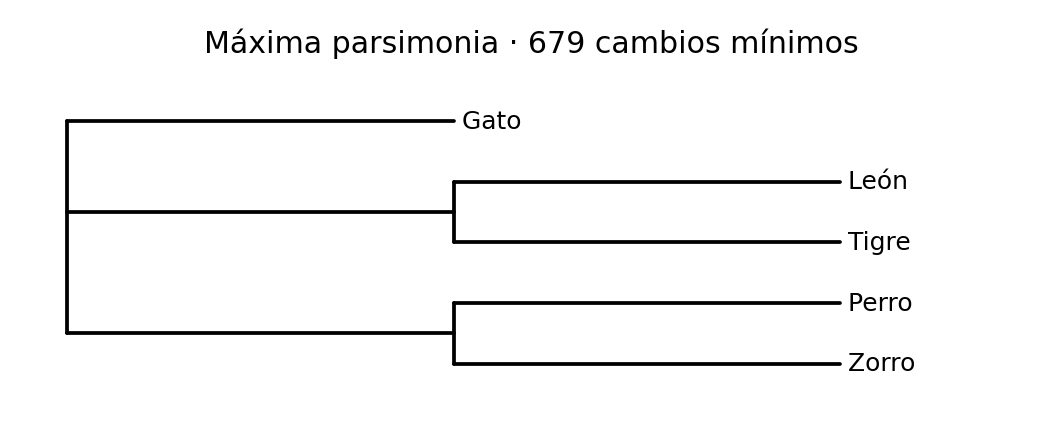

In [9]:
def rama_cladograma(grupo):
    if isinstance(grupo, str):
        return Clade(name=grupo)
    return Clade(clades=[rama_cladograma(subgrupo) for subgrupo in grupo])


mejor_puntuacion, (terminal, subgrupos) = scores[0]
raiz_grafica = Clade(clades=[rama_cladograma(grupo) for grupo in (terminal, *subgrupos)])
arbol_parsimonia = Tree(root=raiz_grafica, rooted=False)

fig, ax = plt.subplots(figsize=(7.2, 2.45))
Phylo.draw(arbol_parsimonia, axes=ax, do_show=False)
ax.set_axis_off()
ax.set_title(f"Máxima parsimonia · {mejor_puntuacion} cambios mínimos", pad=8)
imagen = BytesIO()
fig.savefig(imagen, format="png", dpi=180, bbox_inches="tight", pad_inches=0.16)
display(Image(data=imagen.getvalue()))
plt.close(fig)

## 8. Comparación de resultados

UPGMA comienza por león–tigre, la pareja con menor distancia p. Neighbor-Joining comienza por perro–zorro, la pareja con menor valor de Q. Al comparar los árboles como topologías no enraizadas, los tres métodos recuperan las mismas dos separaciones internas, correspondientes a **león–tigre** y **perro–zorro**.

Neighbor-Joining reproduce con menor error las distancias p observadas en este conjunto. La ventaja de 15 cambios entre las dos primeras topologías de parsimonia indica cuánto difieren sus puntuaciones. El acuerdo entre métodos se refiere al marcador mitocondrial COX1 y a estas cinco secuencias.

El informe incluye una comparación conceptual con máxima verosimilitud e inferencia bayesiana.